In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from IPython.display import display, Image
from sklearn.metrics import roc_auc_score, average_precision_score
from tensorflow import keras


DATA_DIR = "../data"
MODEL_DIR = "../modelos"
FIG_DIR = "../figuras/shap"
RESULTS_DIR = "../resultados"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("SHAP:", shap.__version__)

SHAP: 0.52.0


In [2]:
#Cargamos los datos de train y test
X_train = pd.read_csv(f"{DATA_DIR}/X_train_proc.csv")
X_test = pd.read_csv(f"{DATA_DIR}/X_test_proc.csv")
y_train = pd.read_csv(f"{DATA_DIR}/y_train.csv").iloc[:, 0]
y_test = pd.read_csv(f"{DATA_DIR}/y_test.csv").iloc[:, 0]

feature_names = X_train.columns.tolist() #sacamos lista con los nombres de las varibles caracteristicas
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Variables:", feature_names)

X_train: (27600, 25)
X_test: (6900, 25)
Variables: ['price', 'discount', 'quantity', 'delivery_time_days', 'total_amount', 'shipping_cost', 'profit_margin', 'customer_age', 'category_Electronics', 'category_Fashion', 'category_Grocery', 'category_Home', 'category_Sports', 'category_Toys', 'payment_method_Credit Card', 'payment_method_Debit Card', 'payment_method_PayPal', 'payment_method_UPI', 'payment_method_Wallet', 'region_East', 'region_North', 'region_South', 'region_West', 'customer_gender_Male', 'customer_gender_Other']


In [3]:
#Cargamos los modelos ya entrenados
modelos = {
    "Regresión Logística": joblib.load(f"{MODEL_DIR}/logistic_regression.joblib"),
    "Árbol de Decisión": joblib.load(f"{MODEL_DIR}/decision_tree.joblib"),
    "Random Forest": joblib.load(f"{MODEL_DIR}/random_forest.joblib"),
    "XGBoost": joblib.load(f"{MODEL_DIR}/xgboost_model.joblib")}

c:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.5.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.5.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.5.2 when using version 1.8.0. This might lead 

In [4]:
resultados_shap = {}

# Calculo SHAP de Regresión Logística: LinearExplainer sobre 100 observaciones de fondo.
t = time.time()
fondo = shap.sample(X_train, 100, random_state=RANDOM_STATE) #observaciones de fondo para que SHAP tenga una referencia con la que comparar las predicciones
explainer = shap.LinearExplainer(modelos["Regresión Logística"], fondo) #Objeto que va a realizar las medidas SHAP
sv = np.asarray(explainer.shap_values(X_test)) #array (matriz) con los valores SHAP de cada variable en cada pedido. Miden como contribuye cada variable a la prediccion positiva (devuelto) o no del pedido

#guardamos los resultados del array de valores SHAP, el valor base SHAP de referencia (que se calcula con los 100 datos de fondo del conjunto de entrenamiento) y la escala en la que se encuentran dichos valores SHAP
resultados_shap["Regresión Logística"] = {
    "shap_values": sv,
    "base_value": float(np.ravel(explainer.expected_value)[0]),
    "escala": "logit",
}
print("Regresión Logística:", sv.shape, "tiempo", round(time.time()-t, 2), "s")

Regresión Logística: (6900, 25) tiempo 0.01 s


In [5]:
t = time.time()

# Calculo SHAP de Arbol de Decision: TreeExplainer
explainer = shap.TreeExplainer(modelos["Árbol de Decisión"]) #Objeto que va a realizar las medidas SHAP. Aqui no es necesario fondo para el valor base dado que el explicador ya aprovecha la estructura de arbol del modelo para calcularlo
sv = np.asarray(explainer.shap_values(X_test, check_additivity=False)) #array (matriz) con los valores SHAP de cada variable en cada pedido.
if sv.ndim == 3: #comprobador de que si hay 3 dimensiones (pedidos x variables x clases) te quedas con los valores SHAP correspondientes a la clase "Devuelto" (volvemos a tener pedidos x variables)
    sv = sv[:, :, 1]

#volvemos a guaradar los resultados como en el caso de la Regresion Logistica. Esta vez la escala es probabilistica
resultados_shap["Árbol de Decisión"] = {
    "shap_values": sv,
    "base_value": float(np.ravel(explainer.expected_value)[1] if np.ndim(explainer.expected_value) else explainer.expected_value), #valor base
    "escala": "proba",
}
print("Árbol de Decisión:", sv.shape, "tiempo", round(time.time()-t, 2), "s")

Árbol de Decisión: (6900, 25) tiempo 0.04 s


In [6]:
t = time.time()

# Calculo SHAP de XGBoost: TreeExplainer
explainer = shap.TreeExplainer(modelos["XGBoost"])
sv = np.asarray(explainer.shap_values(X_test, check_additivity=False))
if sv.ndim == 3: 
    sv = sv[:, :, 1]

#volvemos a guardar los resultados. Esta vez la escala es logit para el XGBoost
resultados_shap["XGBoost"] = {
    "shap_values": sv,
    "base_value": float(np.ravel(explainer.expected_value)[1] if np.ndim(explainer.expected_value) else explainer.expected_value), #valor base
    "escala": "proba",
}
print("XGBoost:", sv.shape, "tiempo", round(time.time()-t, 2), "s")

XGBoost: (6900, 25) tiempo 1.03 s


In [7]:
t = time.time()

# Calculo SHAP de Random Forest: TreeExplainer
rf_sample = X_test.iloc[:1000]
explainer = shap.TreeExplainer(modelos["Random Forest"])
sv_rf = np.asarray(explainer.shap_values(rf_sample, check_additivity=False))
if sv_rf.ndim == 3:
    sv_rf = sv_rf[:, :, 1]

#volvemos a guardar los resultados. Esta vez la escala es probabilistica para el Random Forest
resultados_shap["Random Forest"] = {
    "shap_values": sv_rf,
    "base_value": float(np.ravel(explainer.expected_value)[1] if np.ndim(explainer.expected_value) else explainer.expected_value), #valor base
    "escala": "proba",
}

print("Random Forest (1.000 observaciones):", sv_rf.shape, "tiempo", round(time.time()-t, 2), "s")

Random Forest (1.000 observaciones): (1000, 25) tiempo 10.29 s


In [8]:
# Calculo SHAP del MLP: DeepExplainer con 100 valores de fondo
t = time.time()

modelo_mlp = keras.models.load_model(f"{MODEL_DIR}/mlp_keras.keras")

fondo = shap.sample(X_train, 100, random_state=RANDOM_STATE).values #100 valores de fondo
explainer = shap.DeepExplainer(modelo_mlp, fondo)

sv = np.asarray(explainer.shap_values(X_test.values))

if sv.ndim == 3:
    sv = sv[:, :, 0]

#volvemos a guardar los resultados. Esta vez la escala es probabilistica para el MLP
resultados_shap["MLP (Keras)"] = {
    "shap_values": sv,
    "base_value": float(np.ravel(explainer.expected_value)[0]),
    "escala": "proba",
}


print(f"Tiempo de cálculo SHAP MLP: {time.time() - t:.2f} s")

c:\Users\HP\anaconda3\Lib\site-packages\shap\explainers\_deep\deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_24
Received: inputs=['Tensor(shape=(100, 25))']
  warnings.warn(msg)
c:\Users\HP\anaconda3\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_24
Received: inputs=['Tensor(shape=(200, 25))']
  warnings.warn(msg)


Tiempo de cálculo SHAP MLP: 10.48 s


c:\Users\HP\anaconda3\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_24
Received: inputs=['Tensor(shape=(6900, 25))']
  warnings.warn(msg)


C:\Users\HP\AppData\Local\Temp\ipykernel_9860\3301500364.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


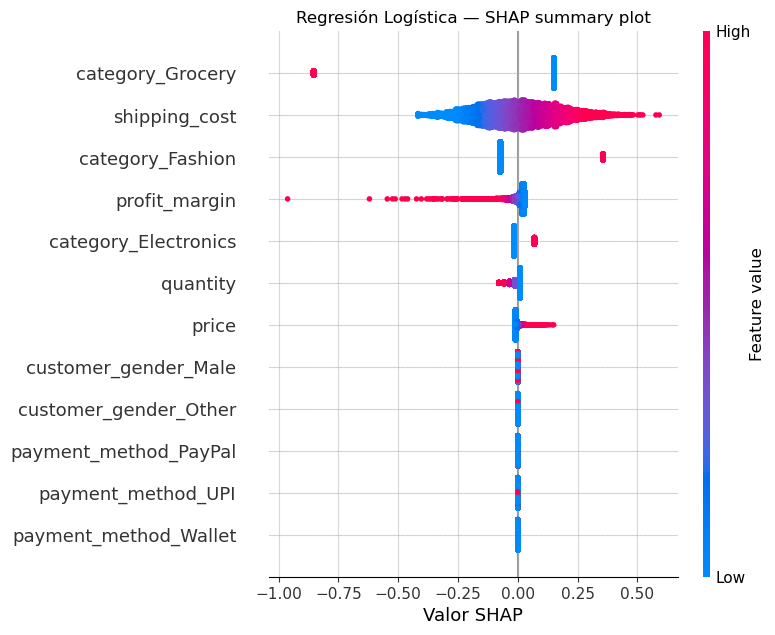

In [9]:
# Código para generar el summary plot de Regresión Logística.
sv_plot = resultados_shap["Regresión Logística"]["shap_values"] #sacamos los SHAP values de la Regresion Logisitca
X_plot = X_test #Quiero que el summary plot use las caracteristicas de los pedidos de X_test

plt.figure()
shap.summary_plot(
    sv_plot,
    X_plot,
    feature_names=feature_names,
    show=False,                         #se genera summnary plot 
    max_display=12,
) 

ax = plt.gca()
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)


plt.xlabel("Valor SHAP")
plt.title("Regresión Logística — SHAP summary plot")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9860\3712106091.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


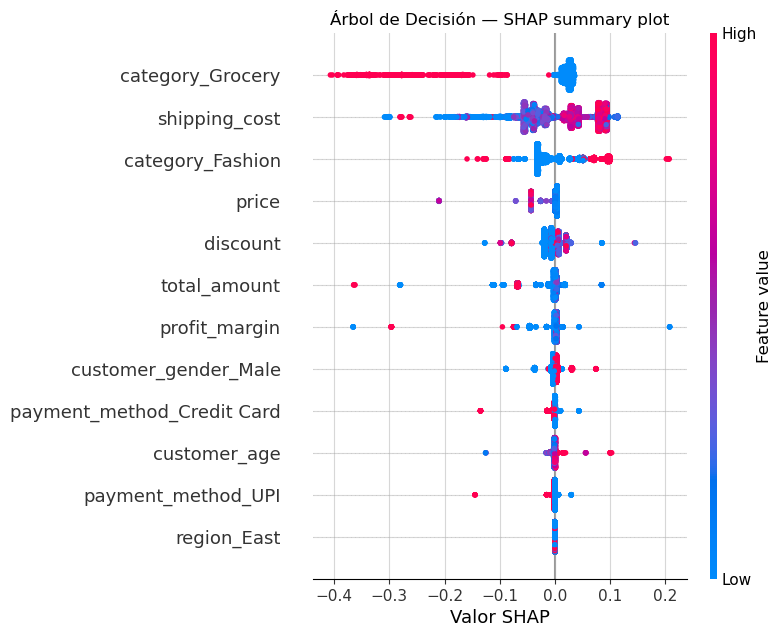

In [10]:
# Código para generar el summary plot de Árbol de Decisión.
sv_plot = resultados_shap["Árbol de Decisión"]["shap_values"]
X_plot = X_test

plt.figure()
shap.summary_plot(
    sv_plot,
    X_plot,
    feature_names=feature_names,
    show=False,
    max_display=12,
)

ax = plt.gca()
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)


plt.xlabel("Valor SHAP")
plt.title("Árbol de Decisión — SHAP summary plot")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9860\2592158185.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


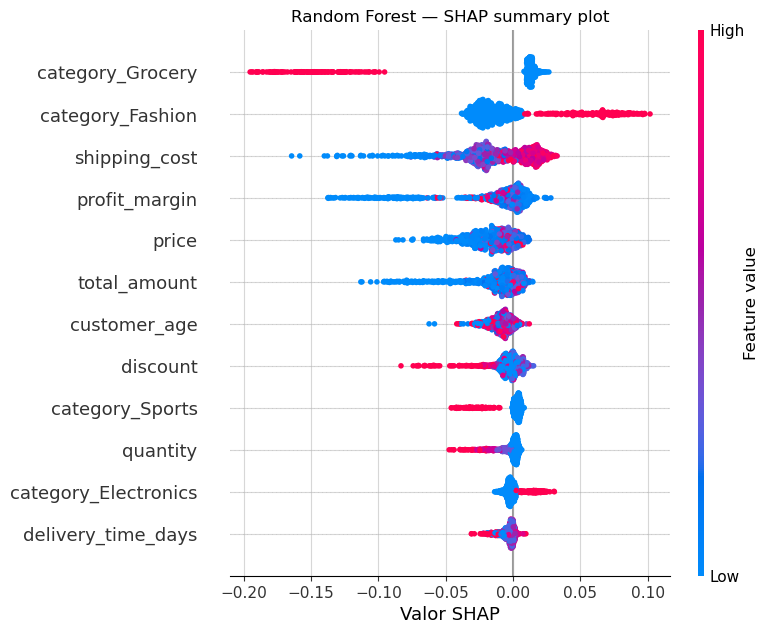

In [11]:
# Código para generar el summary plot de Random Forest.
sv_plot = resultados_shap["Random Forest"]["shap_values"]
X_plot = X_test.iloc[:len(resultados_shap["Random Forest"]["shap_values"])]

plt.figure()
shap.summary_plot(
    sv_plot,
    X_plot,
    feature_names=feature_names,
    show=False,
    max_display=12,
)

ax = plt.gca()
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)


plt.xlabel("Valor SHAP")
plt.title("Random Forest — SHAP summary plot")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9860\2653430212.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


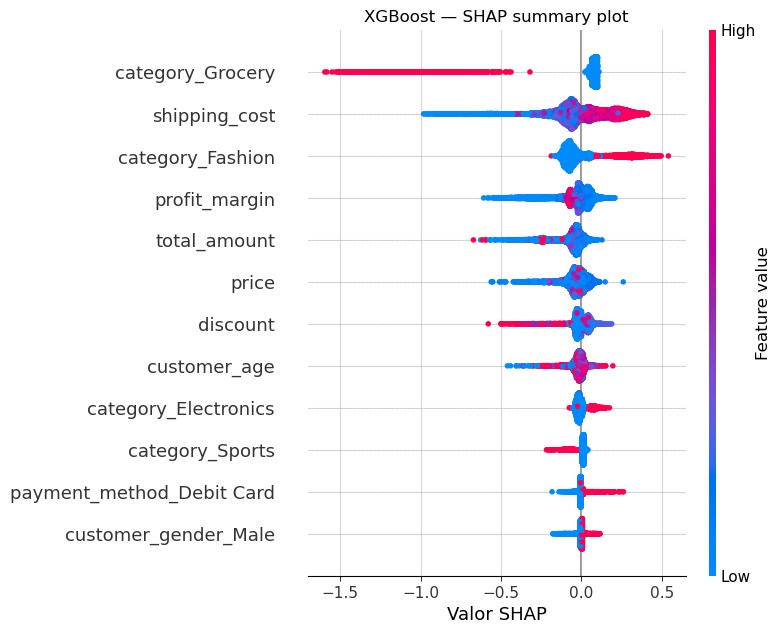

In [12]:
# Código para generar el summary plot de XGBoost.
sv_plot = resultados_shap["XGBoost"]["shap_values"] if "XGBoost" in resultados_shap else sv
X_plot = X_test

plt.figure()
shap.summary_plot(
    sv_plot,
    X_plot,
    feature_names=feature_names,
    show=False,
    max_display=12,
)

ax = plt.gca()
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)

plt.xlabel("Valor SHAP")
plt.title("XGBoost — SHAP summary plot")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_9860\1151116454.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


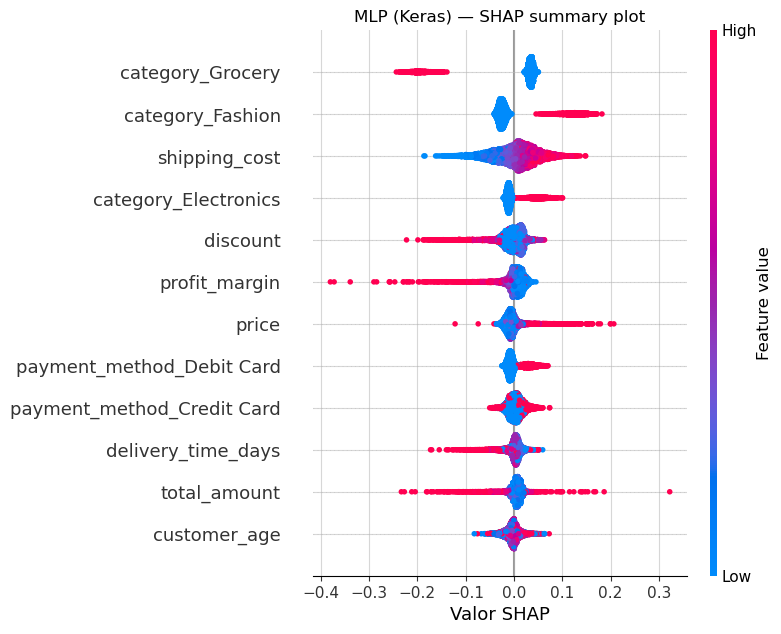

In [13]:
# Código para generar el summary plot del MLP (Keras).
sv_plot = resultados_shap["MLP (Keras)"]["shap_values"]
plt.figure()
shap.summary_plot(
    sv_plot,
    X_test,
    feature_names=feature_names,
    show=False,
    max_display=12,
)

ax = plt.gca()
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)


plt.xlabel("Valor SHAP")
plt.title("MLP (Keras) — SHAP summary plot")
plt.show()

In [14]:
# Valores obtenidos realmente para los modelos calculados aquí.
tabla = pd.DataFrame(index=feature_names)
for nombre in ["Regresión Logística", "Árbol de Decisión", "XGBoost", "Random Forest", "MLP (Keras)"]:
    imp = np.abs(resultados_shap[nombre]["shap_values"]).mean(axis=0) #sacamos los valores medios de importancia SHAP de cada variable
    tabla[nombre] = imp / imp.sum() * 100           #convertimos las importancias a porcentajes


variables_top = [
    "category_Grocery", "shipping_cost", "category_Fashion", "profit_margin",
    "price", "total_amount", "discount", "category_Electronics"
]
tabla_top8 = tabla.loc[variables_top, ["Regresión Logística", "Árbol de Decisión", "Random Forest", "XGBoost", "MLP (Keras)"]].round(2)

tabla_top8.to_csv(f"{RESULTS_DIR}/shap_importancia_top8.csv")
display(tabla_top8)

,Regresión Logística,Árbol de Decisión,Random Forest,XGBoost,MLP (Keras)
category_Grocery,41.55,28.12,15.72,22.430000,15.96
shipping_cost,23.46,27.74,12.72,16.459999,9.74
category_Fashion,21.42,18.79,12.85,12.120000,12.18
profit_margin,4.77,3.74,9.63,8.710000,4.35
price,1.79,6.65,9.43,6.250000,3.89
total_amount,0.00,5.13,7.72,8.450000,3.30
discount,0.00,6.14,3.77,4.720000,5.20
category_Electronics,4.38,0.00,2.35,3.270000,5.22


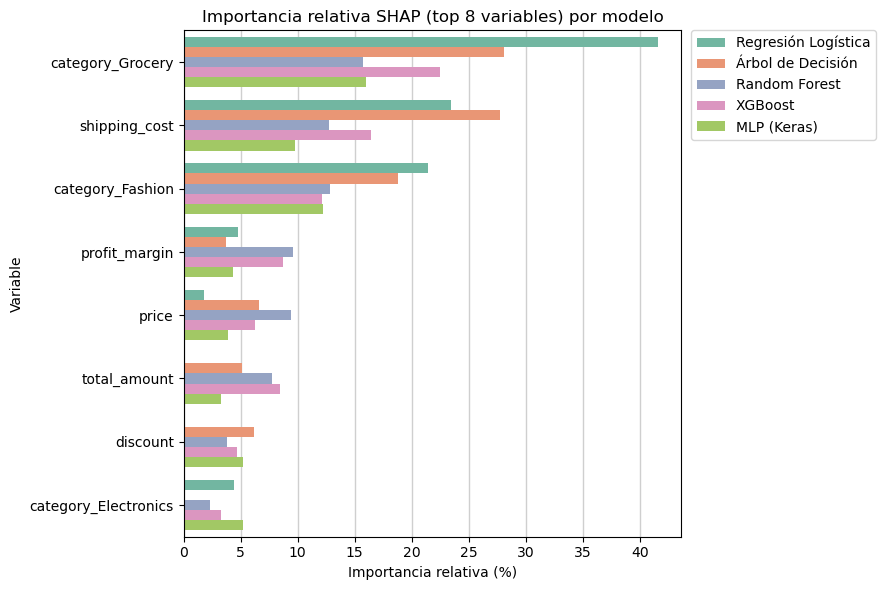

In [15]:
## 5. Comparación de la importancia relativa SHAP

datos_grafico = (
    tabla_top8
    .reset_index()
    .rename(columns={"index": "Variable"})
    .melt(
        id_vars="Variable",
        var_name="Modelo",                           #Establecemos las Variables como indices y pasamos la tabla de formato ancho a formato largo
        value_name="Importancia relativa (%)"
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=datos_grafico,
    y="Variable",
    x="Importancia relativa (%)",
    hue="Modelo",
    palette="Set2",
    ax=ax
)

ax.grid(axis="x", linestyle="-", linewidth=1, alpha=0.6)
ax.set_axisbelow(True)

ax.set_title("Importancia relativa SHAP (top 8 variables) por modelo")

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.tight_layout()
plt.show()